# 04: Warehouse location (CFLP, Phase 4)

This notebook reads the outputs of `python main.py warehouse`. It then re-solves the Puerto Rico CFLP live to show that the model is reproducible.

In [1]:
import sys, os, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_colwidth', 60)
OUT = ROOT / 'data/outputs'
from src.warehouse_cflp import build_problem, solve_cflp, evaluate_configuration
display(pd.read_csv(OUT / 'cflp_solver_report.csv'))
display(pd.read_csv(OUT / 'warehouse_optimization_results.csv'))

,network,method,solver,status,termination,proven_optimal,objective_excl_handling,lower_bound,relative_gap,runtime_s,n_zones,n_candidates,n_variables,n_constraints,time_limit_s,distance_method
0,CONUS,CFLP (Pyomo + CBC),cbc,ok,optimal,True,18348.360207,18348.360207,0.000000e+00,1.018589,312,37,11893,11895,120,haversine_circuity (approximate road km; not a road-netw...
1,Puerto Rico,CFLP (Pyomo + CBC),cbc,ok,optimal,True,2421.759655,2421.759655,1.251524e-12,0.055976,25,25,675,677,120,haversine_circuity (approximate road km; not a road-netw...


,network,method,n_open,opening_cost,transport_cost,handling_cost,cflp_objective_excl_handling,total_cost,avg_distance_km_order_weighted,max_distance_km,mean_utilization,max_utilization,capacity_overload_units,unserved_units,unserved_zones,closed_warehouses_serving,feasible,orders_per_week,units_per_week,runtime_s,termination,relative_gap,annual_total_cost
0,CONUS,CFLP (Pyomo + CBC),6.0,9000.0,9348.360207,148.903802,18348.360207,18497.264009,334.467270,1691.032490,0.620433,0.91104,0.0,0.0,0.0,0.0,True,279.5,297.807605,1.018589,optimal,0.000000e+00,9.618577e+05
1,Puerto Rico,CFLP (Pyomo + CBC),2.0,2400.0,21.759655,87.750000,2421.759655,2509.509655,1.239866,143.972671,0.877500,0.94250,0.0,0.0,0.0,0.0,True,175.5,175.500000,0.055976,optimal,1.251524e-12,1.304945e+05
2,ALL,CFLP (Pyomo + CBC),8.0,11400.0,9370.119861,236.653802,20770.119861,21006.773664,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,True,455.0,473.307605,1.074565,NaN,NaN,1.092352e+06


## Selected warehouses and capacity

,network,warehouse_id,dominant_city,dominant_state,assigned_zones,assigned_orders_per_week,assigned_units_per_week,capacity_units_per_week,utilization_pct
0,CONUS,WH-US-01,Brooklyn,NY,64,70.846084,72.883213,80.0,91.104017
1,CONUS,WH-US-03,Chicago,IL,81,51.184911,55.546983,80.0,69.433729
2,CONUS,WH-US-05,Long Beach,CA,39,65.412505,68.514079,80.0,85.642598
3,CONUS,WH-US-14,Dallas,TX,49,37.428826,40.460937,80.0,50.576171
4,CONUS,WH-US-31,Livermore,CA,48,31.231852,35.235828,80.0,44.044785
5,CONUS,WH-US-37,Hialeah,FL,31,23.395823,25.166565,80.0,31.458206
6,Puerto Rico,WH-PR-03,Caguas,PR,17,94.250000,94.250000,100.0,94.250000
7,Puerto Rico,WH-PR-05,Caguas,PR,8,81.250000,81.250000,100.0,81.250000


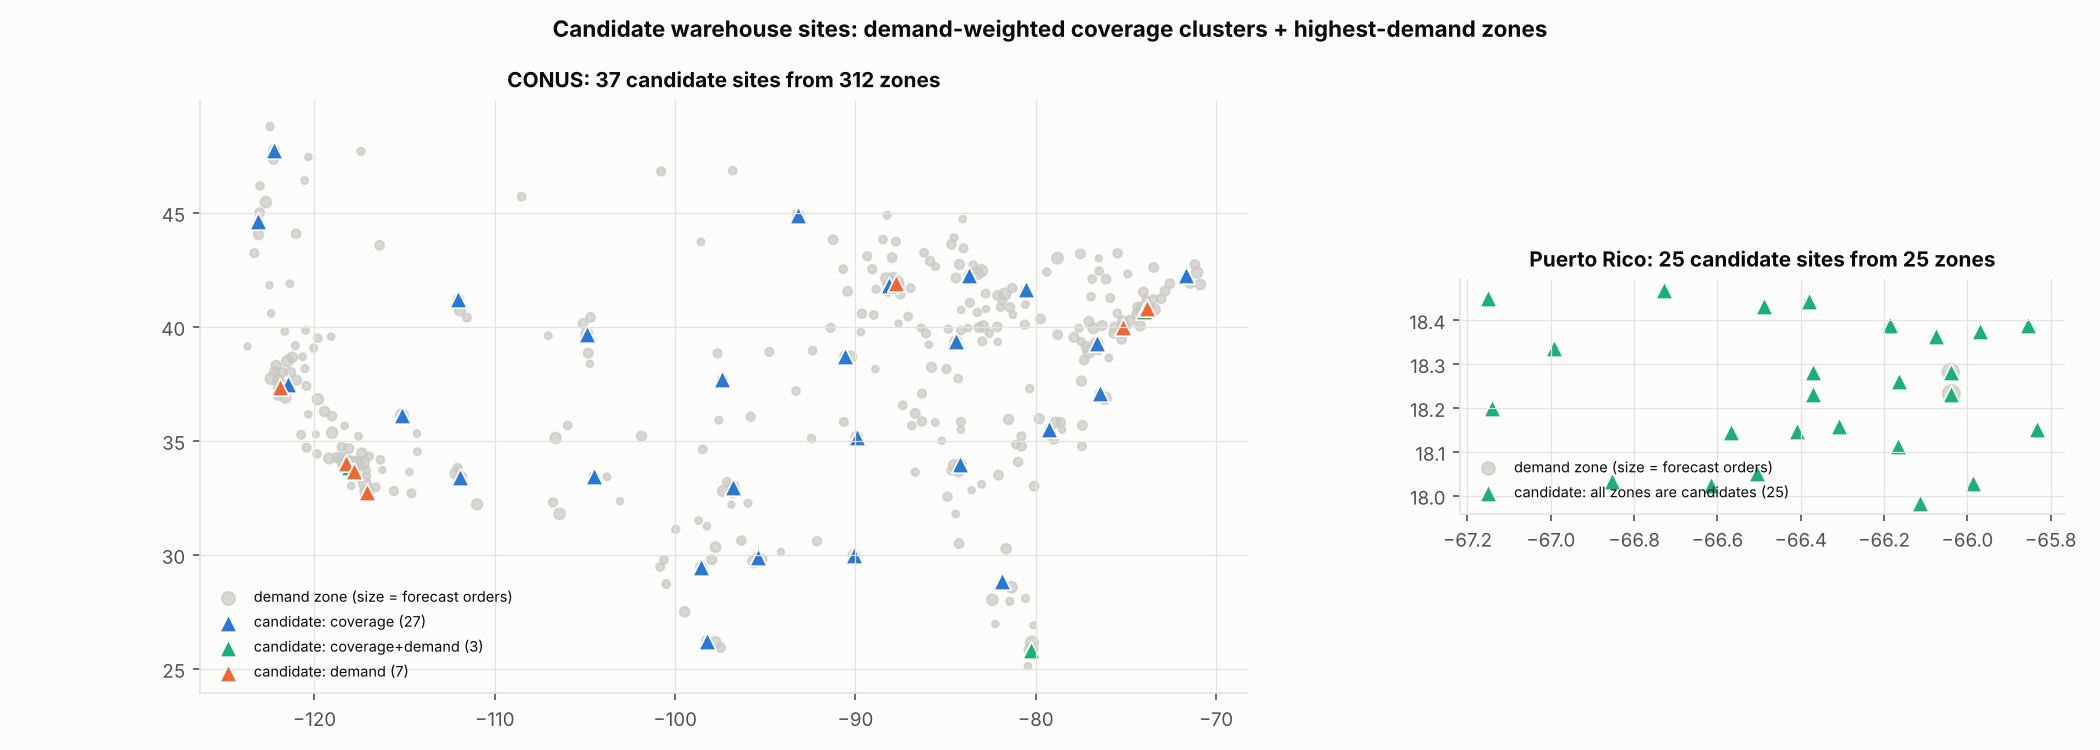

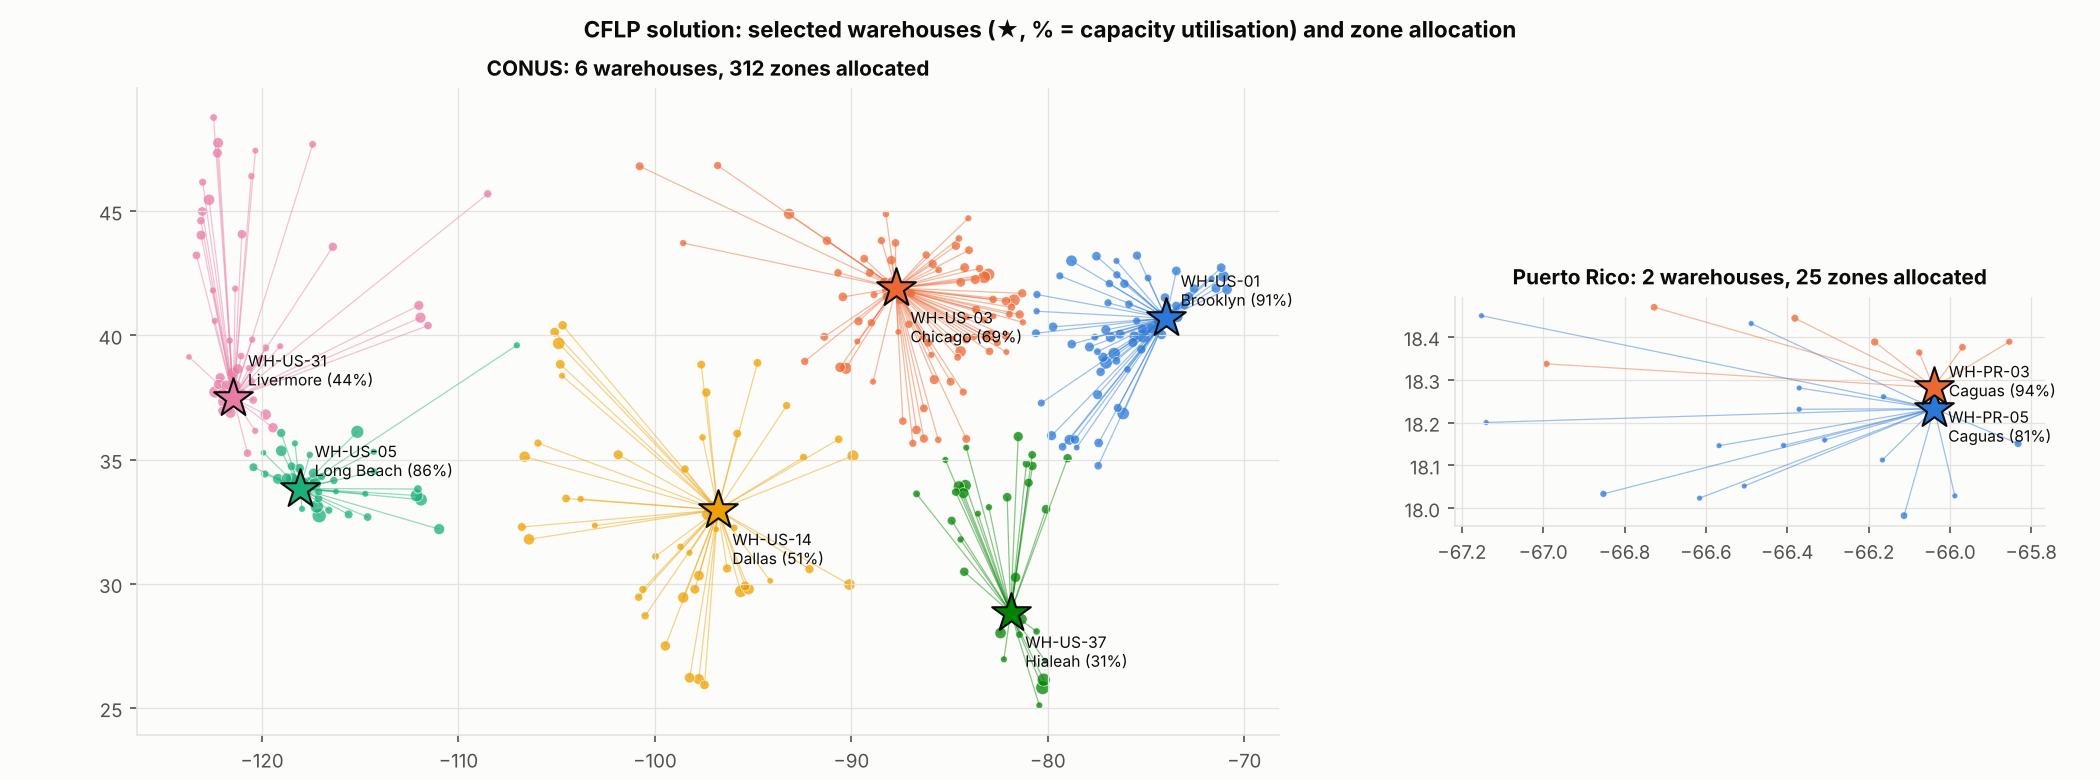

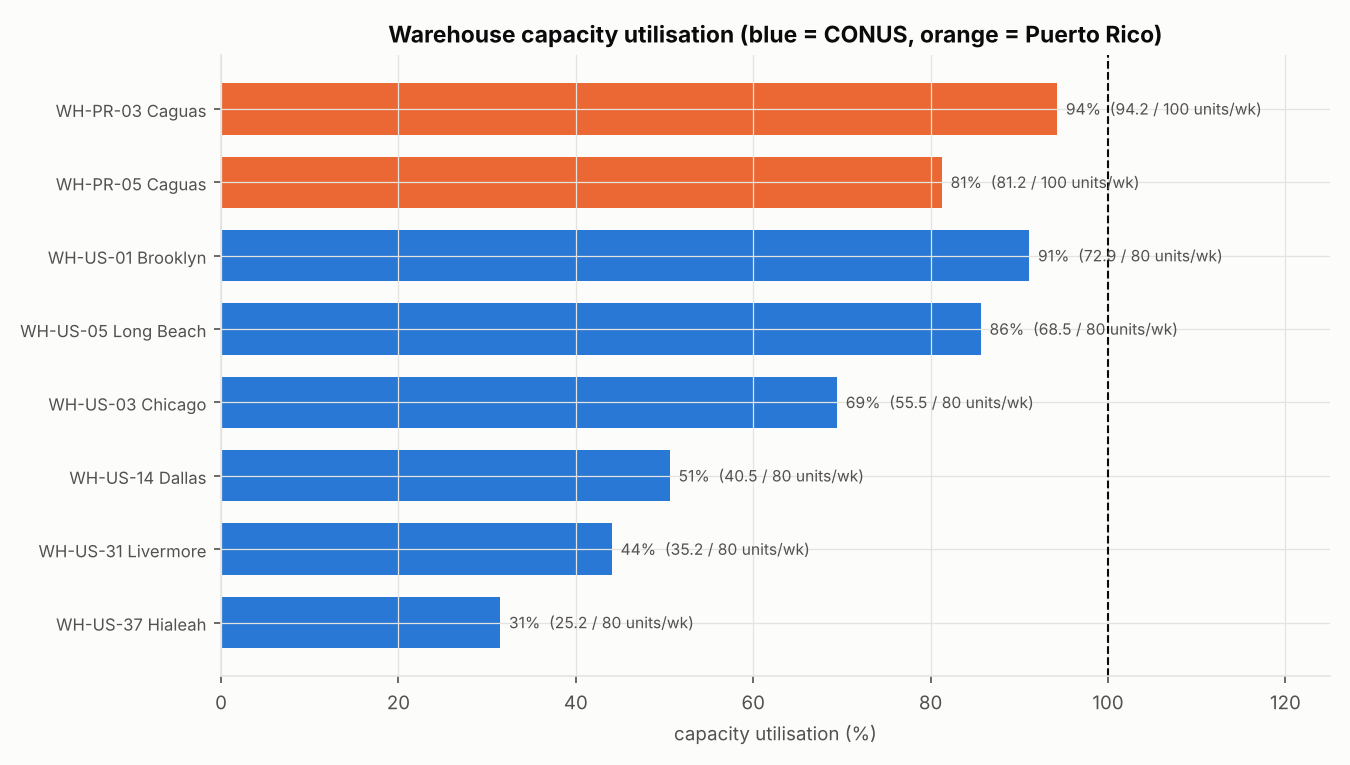

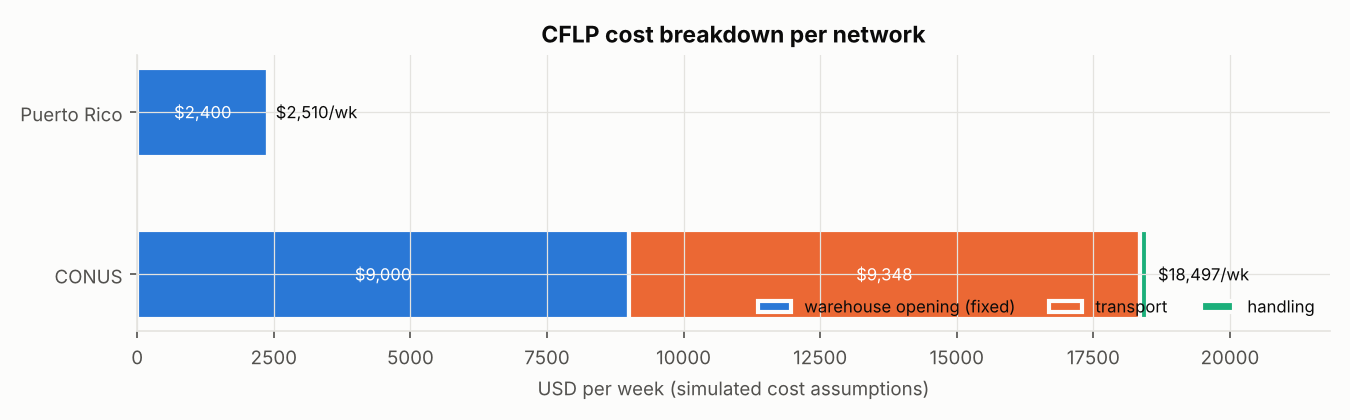

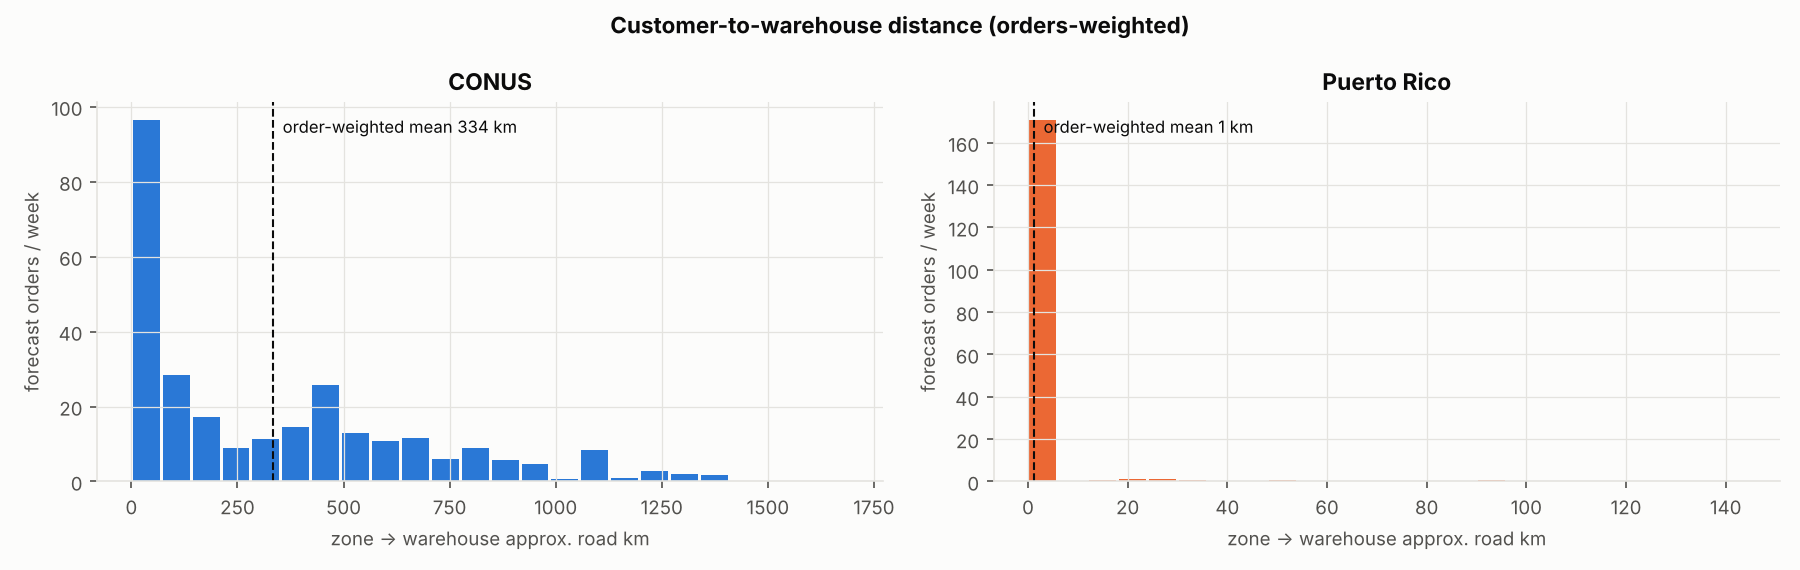

In [2]:
display(pd.read_csv(OUT / 'optimal_warehouse_locations.csv')[['network','warehouse_id','dominant_city','dominant_state','assigned_zones','assigned_orders_per_week','assigned_units_per_week','capacity_units_per_week','utilization_pct']])
for f in ['phase4_candidate_warehouses','phase4_selected_allocation','phase4_warehouse_utilization','phase4_cost_breakdown','phase4_customer_distance']:
    display(Image(f'reports/figures/{f}.png'))

## Live re-solve (Puerto Rico) and independent cost check

In [3]:
prob = build_problem('Puerto Rico')
sol = solve_cflp(prob)
ev = evaluate_configuration(prob, sol.open, sol.assign)
print(sol.termination, round(sol.objective, 4), 'open:', list(prob.candidates.warehouse_id[sol.open]))
print('recomputed opening + transport:', round(ev['opening_cost'] + ev['transport_cost'], 4), '| feasible:', ev['feasible'])

optimal 2421.7597 open: ['WH-PR-03', 'WH-PR-05']
recomputed opening + transport: 2421.7597 | feasible: True
